### 🏗️ Mini Project

"Employee Salary Predictor Using Decision Tree"

- Dataset: years_experience, education_level (encoded), department (encoded) → salary
- Implement the model both from scratch and with scikit-learn
- Visualise the tree with plot_tree()
- Compare train/test error for different max_depth values (1, 3, 5, None), as was done for the degree in Polynomial Regression
- Identify the best max_depth and explain why

In [55]:
import numpy as np
import pandas as pd

num_employees = 100
np.random.seed(42)

# 1. Base features
experience = np.random.randint(0, 20, num_employees)
education_levels = ['High School', 'Bachelor', 'Master', 'PhD']
departments = ['HR', 'Finance', 'Engineering', 'Marketing', 'Sales']

education = np.random.choice(education_levels, num_employees)
department = np.random.choice(departments, num_employees)

# 2. Map structural bonuses to education and department
edu_bonus = {'High School': 0, 'Bachelor': 15000, 'Master': 30000, 'PhD': 45000}
dept_bonus = {'HR': 0, 'Sales': 5000, 'Marketing': 8000, 'Finance': 12000, 'Engineering': 20000}

# 3. Calculate salary logically: Base + Experience Pay + Edu Bonus + Dept Bonus + Random Noise
base_salary = 30000
salary = []

for idx in range(num_employees):
    exp_pay = experience[idx] * 2000
    e_bonus = edu_bonus[education[idx]]
    d_bonus = dept_bonus[department[idx]]
    
    # Add minor random variation so it looks natural, but keeps the underlying rules
    random_noise = np.random.randint(-5000, 5000) 
    
    total_salary = base_salary + exp_pay + e_bonus + d_bonus + random_noise
    salary.append(total_salary)

# 4. Create DataFrame
df = pd.DataFrame({
    'Experience': experience,
    'Education': education,
    'Department': department,
    'Salary': salary
})
df.head()

,Experience,Education,Department,Salary
0,6,Master,HR,71493
1,19,PhD,Marketing,125492
2,14,PhD,HR,102911
3,10,Bachelor,HR,63987
4,7,Master,Finance,90719


In [56]:
from sklearn. preprocessing import OrdinalEncoder

# Encode categorical features
ordinal_encoder = OrdinalEncoder()
df[['Education']] = ordinal_encoder.fit_transform(df[['Education']])


df = pd.get_dummies(df, columns=['Department'], dtype=int)

df.head()

,Experience,Education,Salary,Department_Engineering,Department_Finance,Department_HR,Department_Marketing,Department_Sales
0,6,2.0,71493,0,0,1,0,0
1,19,3.0,125492,0,0,0,1,0
2,14,3.0,102911,0,0,1,0,0
3,10,0.0,63987,0,0,1,0,0
4,7,2.0,90719,0,1,0,0,0


In [57]:
# From Scratch Decision Tree Implementation

import numpy as np

def calculate_variance(y):
    if len(y) == 0:
        return 0
    return np.var(y)

def weighted_variance(y_left, y_right):
    n_left, n_right = len(y_left), len(y_right)
    total_length = n_left + n_right
    if total_length == 0:
        return 0

    weighted_var = (n_left / total_length) * calculate_variance(y_left) + (n_right / total_length) * calculate_variance(y_right)
    return weighted_var

In [58]:
def find_best_split(X, y):
    n_samples, n_features = X.shape
    best_feature = None
    best_threshold = None
    best_variance = float('inf')

    for feature_index in range(n_features):
        thresholds = np.unique(X[:, feature_index])
        for threshold in thresholds:
            left_indices = X[:, feature_index] <= threshold
            right_indices = X[:, feature_index] > threshold

            y_left, y_right = y[left_indices], y[right_indices]
            current_variance = weighted_variance(y_left, y_right)

            if current_variance < best_variance:
                best_variance = current_variance
                best_feature = feature_index
                best_threshold = threshold

    return best_feature, best_threshold, best_variance

In [59]:
class Node:
    def __init__(self, feature_index=None, threshold=None, left=None, right=None, value=None):
        self.feature_index = feature_index
        self.threshold = threshold
        self.left = left
        self.right = right
        self.value = value

    def is_leaf_node(self):
        return self.value is not None

In [60]:
def build_tree(X, y, depth=0, max_depth=None):
    n_samples, n_features = X.shape

    # Stopping conditions
    if n_samples == 0 or (max_depth is not None and depth >= max_depth):
        return None

    # If all target values are the same, create a leaf node
    if len(np.unique(y)) == 1:
        return Node(value=y[0])

    # Find the best split
    feature_index, threshold, variance = find_best_split(X, y)

    if feature_index is None:
        return Node(value=np.mean(y))

    # Split the dataset
    left_indices = X[:, feature_index] <= threshold
    right_indices = X[:, feature_index] > threshold

    left_child = build_tree(X[left_indices], y[left_indices], depth + 1, max_depth)
    right_child = build_tree(X[right_indices], y[right_indices], depth + 1, max_depth)

    return Node(feature_index=feature_index, threshold=threshold, left=left_child, right=right_child)

In [61]:
X = df.drop(columns=['Salary']).values
y = df['Salary'].values

best_feature, best_threshold, best_variance = find_best_split(X, y)
print(f"Best feature index: {best_feature}, Best threshold: {best_threshold}, Variance: {best_variance:.2f}")

tree = build_tree(X, y, max_depth=3)

Best feature index: 1, Best threshold: 1.0, Variance: 226858064.72


In [62]:
def predict(node, x):
    if node.is_leaf_node():
        return node.value

    if x[node.feature_index] <= node.threshold:
        return predict(node.left, x)
    else:
        return predict(node.right, x)

Depth 2: Train MSE = 101995699.42, Test MSE = 155858761.81
Depth 2: Difference: -53863062.39
Depth 3: Train MSE = 70345065.19, Test MSE = 147441332.22
Depth 3: Difference: -77096267.03
Depth 4: Train MSE = 37310784.60, Test MSE = 123503266.40
Depth 4: Difference: -86192481.80
Depth 5: Train MSE = 14601082.53, Test MSE = 96409572.49
Depth 5: Difference: -81808489.96
Depth 6: Train MSE = 3924153.46, Test MSE = 70112806.99
Depth 6: Difference: -66188653.52
Depth 7: Train MSE = 1265239.78, Test MSE = 62559707.38
Depth 7: Difference: -61294467.59
Depth 8: Train MSE = 952713.09, Test MSE = 68762536.31
Depth 8: Difference: -67809823.22
Depth None: Train MSE = 820256.22, Test MSE = 61060248.15
Depth None: Difference: -60239991.92


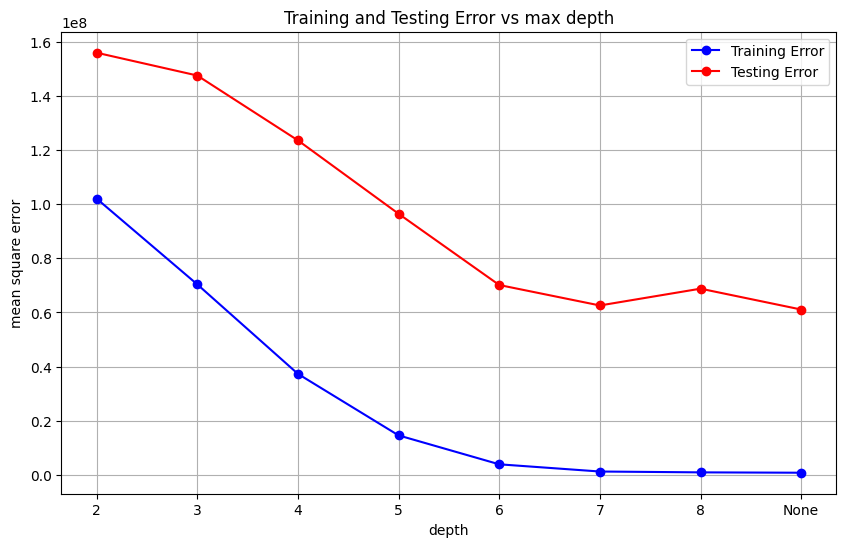

In [68]:
# Sklearn Decision Tree Implementation
from sklearn.model_selection import train_test_split
from sklearn.tree import DecisionTreeRegressor
import matplotlib.pyplot as plt
from sklearn.metrics import mean_squared_error

X = df.drop(columns=['Salary']).values
y = df['Salary'].values

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

train_error = []
test_error = []
max_d = max_d = [2, 3, 4, 5, 6, 7, 8, None]

for depth in max_d:

    tree_model = DecisionTreeRegressor(max_depth=depth, random_state=42)

    tree_model.fit(X_train, y_train)

    train_pred = tree_model.predict(X_train)
    test_pred = tree_model.predict(X_test)

    train_mse = mean_squared_error(y_train, train_pred)
    test_mse = mean_squared_error(y_test, test_pred)

    train_error.append(train_mse)
    test_error.append(test_mse)

    print(f"Depth {depth}: Train MSE = {train_mse:.2f}, Test MSE = {test_mse:.2f}")

    print(f'Depth {depth}: Difference: {train_mse- test_mse:.2f}')

x_labels = [str(d) for d in max_d]

plt.figure(figsize=(10,6))
plt.plot(x_labels, train_error, marker='o', label='Training Error', color='blue')
plt.plot(x_labels, test_error, marker='o', label='Testing Error', color='red')

plt.title('Training and Testing Error vs max depth')
plt.xlabel('depth')
plt.ylabel('mean square error')
plt.legend()
plt.grid(True)
plt.show()

In [67]:
# best depth 

best_depth = 7

tree_model = DecisionTreeRegressor(max_depth=best_depth, random_state=42)

tree_model.fit(X_train, y_train)

train_pred = tree_model.predict(X_train)
test_pred = tree_model.predict(X_test)

train_mse = mean_squared_error(y_train, train_pred)
test_mse = mean_squared_error(y_test, test_pred)

print(f"Best Depth: {best_depth}")
print(f"Training Error: {train_mse:.2f}")
print(f"Testing Error: {test_mse:.2f}")

Best Depth: 7
Training Error: 1265239.78
Testing Error: 62559707.38
